## Dataset Information

### Data Source

This analysis uses the **Air Quality Monitoring in European Cities** dataset from Kaggle:

[Air Quality Monitoring in European Cities](https://www.kaggle.com/datasets/yekenot/air-quality-monitoring-in-european-cities)

### Dataset Used

The Athens subset, `athens_data.csv`, contains 1,726,464 hourly observations and 19 columns, covering the period from May 2020 to May 2023.

### Download Instructions

The original CSV file is not included in this GitHub repository because of its large file size (approximately 438 MB).

To run this notebook:

1. Download the dataset from Kaggle.
2. Extract `athens_data.csv`.
3. Place it in the `data/` folder at the project root.

Expected structure:

```text
Data_Science_Athens/
├── data/
│   └── athens_data.csv
└── query2/
    └── Query2_Frequent_Pattern_Mining.ipynb
```

The notebook loads the dataset using the relative path `../data/athens_data.csv`.

# Query 2 — Frequent Pattern Mining

## Environmental Conditions Associated with High PM2.5 Concentrations in Athens

### Research Question

Which environmental conditions frequently occur together with high PM2.5 concentrations in Athens?

### Objective

The objective of this analysis is to discover frequent patterns and association rules between air pollution levels and environmental conditions, including relative humidity, temperature, and wind speed.

### Methodology

We will use the Apriori algorithm to identify frequent itemsets and association rule mining to discover relationships between environmental conditions and high PM2.5 concentrations.

The analysis will focus on co-occurrence patterns. Association rules will not be interpreted as evidence of causation.

In [2]:
%pip install mlxtend

  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 37.7 MB/s  0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 9.3/9.3 MB 47.3 MB/s  0:00:00
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 8.2/8.2 MB 85.1 MB/s  0:00:00

  Attempting uninstall: scikit-learn

    Found existing installation: scikit-learn 1.7.2

   ---------------------------------------- 0/3 [scikit-learn]
    Uninstalling scikit-learn-1.7.2:
   ---------------------------------------- 0/3 [scikit-learn]
      Successfully uninstalled scikit-learn-1.7.2
   ---------------------------------------- 0/3 [scikit-learn]
   ---------------------------------------- 0/3 [

In [60]:
from IPython.display import display
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.cluster import DBSCAN
from sklearn.metrics import mean_absolute_error, mean_squared_error
from mlxtend.frequent_patterns import apriori, association_rules

In [31]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


from IPython.display import display
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.cluster import DBSCAN
from sklearn.metrics import mean_absolute_error, mean_squared_error
from mlxtend.frequent_patterns import apriori, association_rules

print("Current working directory:", Path.cwd())

data_path = Path("data/athens_data.csv")

print("Dataset exists:", data_path.exists())

if data_path.exists():
    print("Dataset size (MB):", round(data_path.stat().st_size / (1024 ** 2), 2))

KeyboardInterrupt: 

In [61]:
# Load only the variables required for Query 2

columns_to_load = [
    "Date",
    "station_name",
    "PM2.5",
    "Relative Humidity",
    "Temp",
    "Wind-Speed (U)",
    "Wind-Speed (V)"
]

df = pd.read_csv(
    data_path,
    usecols=columns_to_load,
    parse_dates=["Date"]
)

print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1726464, 7)

First five rows:


,Date,station_name,Wind-Speed (U),Wind-Speed (V),Temp,Relative Humidity,PM2.5
0,2020-05-01,Athens CAMS station 0,1.713115,-0.588855,12.948856,82.578812,6.200135
1,2020-05-01,Athens CAMS station 9,1.960498,-0.937417,14.011539,78.352731,7.836725
2,2020-05-01,Athens CAMS station 1,1.640985,-0.556073,12.550690,82.840317,6.306404
3,2020-05-01,Athens CAMS station 10,2.003834,-0.971722,14.261641,76.558915,8.207660
4,2020-05-01,Athens CAMS station 11,1.954063,-0.912335,14.179075,76.140202,8.217451



Data types:
Date                 datetime64[ns]
station_name                 object
Wind-Speed (U)              float64
Wind-Speed (V)              float64
Temp                        float64
Relative Humidity           float64
PM2.5                       float64
dtype: object

Missing values:
Date                    0
station_name            0
Wind-Speed (U)       8573
Wind-Speed (V)       8573
Temp                 7565
Relative Humidity    8573
PM2.5                   0
dtype: int64


In [62]:
# Calculate descriptive statistics

variables = [
    "PM2.5",
    "Relative Humidity",
    "Temp",
    "Wind-Speed (U)",
    "Wind-Speed (V)"
]

print("Descriptive statistics:")
display(df[variables].describe())

# Calculate wind speed magnitude from U and V components
df["Wind Speed"] = np.sqrt(
    df["Wind-Speed (U)"] ** 2 +
    df["Wind-Speed (V)"] ** 2
)

print("\nWind speed statistics:")
display(df["Wind Speed"].describe())

# Calculate selected quantiles
print("\nSelected quantiles:")
display(
    df[["PM2.5", "Relative Humidity", "Temp", "Wind Speed"]]
    .quantile([0.25, 0.50, 0.75])
)

Descriptive statistics:


,PM2.5,Relative Humidity,Temp,Wind-Speed (U),Wind-Speed (V)
count,1.726464e+06,1.717891e+06,1.718899e+06,1.717891e+06,1.717891e+06
mean,1.507474e+01,6.482702e+01,1.732727e+01,3.049955e-01,-1.022836e+00
std,1.506120e+01,2.045157e+01,7.935267e+00,1.129302e+00,2.476726e+00
min,0.000000e+00,8.917820e+00,-3.285516e+00,-5.614838e+00,-9.550298e+00
25%,8.000000e+00,4.894963e+01,1.130130e+01,-3.956884e-01,-2.644421e+00
50%,1.165063e+01,6.715539e+01,1.653857e+01,2.714379e-01,-1.078331e+00
75%,1.776377e+01,8.180991e+01,2.326301e+01,8.887634e-01,7.087822e-01
max,1.748715e+03,9.993658e+01,4.260825e+01,7.170837e+00,1.007972e+01



Wind speed statistics:


count    1.717891e+06
mean     2.509095e+00
std      1.501049e+00
min      3.089393e-03
25%      1.368555e+00
50%      2.171785e+00
75%      3.373695e+00
max      1.020407e+01
Name: Wind Speed, dtype: float64


Selected quantiles:


,PM2.5,Relative Humidity,Temp,Wind Speed
0.25,8.000000,48.949630,11.301296,1.368555
0.50,11.650626,67.155393,16.538572,2.171785
0.75,17.763765,81.809910,23.263008,3.373695


In [63]:
# Inspect spatial and temporal structure

print("Number of monitoring stations:")
print(df["station_name"].nunique())

print("\nMonitoring stations:")
print(df["station_name"].value_counts())

print("\nDate range:")
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

print("\nNumber of unique dates:")
print(df["Date"].dt.date.nunique())

print("\nRecords per monitoring station:")
display(
    df.groupby("station_name")
    .size()
    .sort_values(ascending=False)
    .rename("number_of_records")
    .to_frame()
)

print("\nDuplicate rows:")
print(df.duplicated().sum())

Number of monitoring stations:
64

Monitoring stations:
station_name
Athens CAMS station 0    26976
Athens CAMS station 9    26976
ATHENS_02                26976
PANACEA_001              26976
PANACEA_000              26976
                         ...  
KOROPI                   26976
PERISTERI                26976
Ano Liosia (Perneri)     26976
ATHINAS                  26976
PANACEA_006              26976
Name: count, Length: 64, dtype: int64

Date range:
Start: 2020-05-01 00:00:00
End: 2023-05-29 23:00:00

Number of unique dates:
1124

Records per monitoring station:


,number_of_records
station_name,
ARISTOTELOUS,26976
ATH-ENVICARE-0,26976
PANACEA_000,26976
PANACEA_001,26976
PANACEA_004,26976
...,...
Athens CAMS station 8,26976
Athens CAMS station 9,26976
CleanAir in Greece - Thiseio,26976



Duplicate rows:
0


## Data Preparation — Daily Aggregation

The original dataset contains hourly observations from 64 monitoring stations over 1,124 days.

To reduce computational complexity and focus on daily environmental conditions, we aggregate the hourly observations into daily records for each monitoring station.

For each station and day, we calculate the daily mean of PM2.5, relative humidity, temperature, and wind speed.

The resulting dataset represents station-day observations. This aggregation preserves both temporal and spatial information while reducing the number of observations.

In [64]:
# Aggregate hourly observations into station-day records

df["Date_day"] = df["Date"].dt.floor("D")

daily_df = (
    df.groupby(["station_name", "Date_day"])
    .agg(
        PM25=("PM2.5", "mean"),
        Humidity=("Relative Humidity", "mean"),
        Temperature=("Temp", "mean"),
        Wind_Speed=("Wind Speed", "mean")
    )
    .reset_index()
)

print("Daily dataset shape:", daily_df.shape)

print("\nFirst five daily observations:")
display(daily_df.head())

print("\nMissing values after aggregation:")
print(daily_df.isnull().sum())

print("\nDaily descriptive statistics:")
display(
    daily_df[
        ["PM25", "Humidity", "Temperature", "Wind_Speed"]
    ].describe()
)

Daily dataset shape: (71936, 6)

First five daily observations:


,station_name,Date_day,PM25,Humidity,Temperature,Wind_Speed
0,ARISTOTELOUS,2020-05-01,39.250000,59.372910,18.690502,2.400516
1,ARISTOTELOUS,2020-05-02,11.541667,56.444677,19.009520,2.581848
2,ARISTOTELOUS,2020-05-03,10.958333,58.707806,18.646729,2.228816
3,ARISTOTELOUS,2020-05-04,4.125000,55.547500,16.075749,2.637720
4,ARISTOTELOUS,2020-05-05,8.625000,54.491966,17.190038,2.019387



Missing values after aggregation:
station_name      0
Date_day          0
PM25              0
Humidity        351
Temperature     309
Wind_Speed      351
dtype: int64

Daily descriptive statistics:


,PM25,Humidity,Temperature,Wind_Speed
count,71936.000000,71585.000000,71627.000000,71585.000000
mean,15.074738,64.827358,17.326956,2.509081
std,10.339701,13.793413,7.270347,1.202095
min,0.062491,27.789733,-0.966513,0.487196
25%,8.958333,53.791386,11.548742,1.543642
50%,12.268236,65.391014,16.465952,2.226428
75%,17.912190,75.831245,23.914223,3.253897
max,474.162974,96.398554,34.875799,8.042126


## Discretization — Converting Continuous Variables into Categories

The four numerical variables are transformed into three categorical levels: Low, Medium, and High.

The thresholds are determined using the first quartile (Q1) and third quartile (Q3) of each variable.

- Low: values less than or equal to Q1
- Medium: values greater than Q1 and less than or equal to Q3
- High: values greater than Q3

This quantile-based discretization provides a consistent way to transform continuous measurements into categorical items for frequent pattern mining.

High PM2.5 represents a relative high-concentration category within this dataset, not a regulatory air-quality threshold.

In [65]:
# Define variables for frequent pattern mining

analysis_columns = [
    "PM25",
    "Humidity",
    "Temperature",
    "Wind_Speed"
]

# Calculate quartile thresholds
thresholds = daily_df[analysis_columns].quantile([0.25, 0.75])

print("Quartile thresholds:")
display(thresholds)

# Remove observations with missing analysis variables
mining_df = daily_df.dropna(subset=analysis_columns).copy()

print("Original observations:", len(daily_df))
print("Observations after removing missing values:", len(mining_df))
print("Removed observations:", len(daily_df) - len(mining_df))

# Convert continuous variables into Low, Medium, High categories
for column in analysis_columns:
    q1 = thresholds.loc[0.25, column]
    q3 = thresholds.loc[0.75, column]

    mining_df[column + "_Level"] = pd.cut(
        mining_df[column],
        bins=[-np.inf, q1, q3, np.inf],
        labels=["Low", "Medium", "High"]
    )

# Inspect categorical distributions
categorical_columns = [
    "PM25_Level",
    "Humidity_Level",
    "Temperature_Level",
    "Wind_Speed_Level"
]

for column in categorical_columns:
    print(f"\n{column}:")
    display(mining_df[column].value_counts().sort_index())

Quartile thresholds:


,PM25,Humidity,Temperature,Wind_Speed
0.25,8.958333,53.791386,11.548742,1.543642
0.75,17.912190,75.831245,23.914223,3.253897


Original observations: 71936
Observations after removing missing values: 71585
Removed observations: 351

PM25_Level:


PM25_Level
Low       17986
Medium    35793
High      17806
Name: count, dtype: int64


Humidity_Level:


Humidity_Level
Low       17897
Medium    35792
High      17896
Name: count, dtype: int64


Temperature_Level:


Temperature_Level
Low       17875
Medium    35803
High      17907
Name: count, dtype: int64


Wind_Speed_Level:


Wind_Speed_Level
Low       17897
Medium    35792
High      17896
Name: count, dtype: int64

## Transaction Encoding — One-Hot Encoding

Each station-day observation is represented as a transaction containing four categorical items: PM2.5 level, humidity level, temperature level, and wind speed level.

We apply one-hot encoding to transform categorical variables into Boolean features.

A value of True indicates that the corresponding condition is present in the observation, while False indicates that it is absent.

This transaction representation is used as input for the Apriori algorithm.

In [66]:
# Convert categorical variables into one-hot encoded transactions

transactions = pd.get_dummies(
    mining_df[categorical_columns],
    prefix=categorical_columns,
    dtype=bool
)

print("Transaction dataset shape:", transactions.shape)

print("\nTransaction matrix:")
display(transactions.head())

print("\nNumber of items per transaction:")
display(transactions.sum(axis=1).value_counts().sort_index())

print("\nFrequency of each item:")
display(
    transactions.sum()
    .sort_values(ascending=False)
    .to_frame(name="frequency")
)

Transaction dataset shape: (71585, 12)

Transaction matrix:


,PM25_Level_Low,PM25_Level_Medium,PM25_Level_High,Humidity_Level_Low,Humidity_Level_Medium,Humidity_Level_High,Temperature_Level_Low,Temperature_Level_Medium,Temperature_Level_High,Wind_Speed_Level_Low,Wind_Speed_Level_Medium,Wind_Speed_Level_High
0,False,False,True,False,True,False,False,True,False,False,True,False
1,False,True,False,False,True,False,False,True,False,False,True,False
2,False,True,False,False,True,False,False,True,False,False,True,False
3,True,False,False,False,True,False,False,True,False,False,True,False
4,True,False,False,False,True,False,False,True,False,False,True,False



Number of items per transaction:


4    71585
Name: count, dtype: int64


Frequency of each item:


,frequency
Temperature_Level_Medium,35803
PM25_Level_Medium,35793
Humidity_Level_Medium,35792
Wind_Speed_Level_Medium,35792
PM25_Level_Low,17986
Temperature_Level_High,17907
Humidity_Level_Low,17897
Wind_Speed_Level_Low,17897
Humidity_Level_High,17896
Wind_Speed_Level_High,17896


### Frequent Itemset Mining — Apriori Algorithm

We apply the Apriori algorithm to identify frequent combinations of environmental conditions in Athens.

The minimum support threshold is set to 0.05, meaning that an itemset must appear in at least 5% of all station-day observations to be considered frequent.

This threshold helps remove rare combinations and focus on recurring environmental patterns.

We use a maximum itemset length of 4 because each transaction contains four environmental variables.

In [67]:
# Apply the Apriori algorithm

frequent_itemsets = apriori(
    transactions,
    min_support=0.05,
    use_colnames=True,
    max_len=4
)

# Sort frequent itemsets by support
frequent_itemsets = frequent_itemsets.sort_values(
    by="support",
    ascending=False
).reset_index(drop=True)

print("Number of frequent itemsets:", len(frequent_itemsets))

print("\nTop 20 frequent itemsets:")
display(frequent_itemsets.head(20))

Number of frequent itemsets: 90

Top 20 frequent itemsets:


,support,itemsets
0,0.500147,(Temperature_Level_Medium)
1,0.500007,(PM25_Level_Medium)
2,0.499993,(Wind_Speed_Level_Medium)
3,0.499993,(Humidity_Level_Medium)
4,0.318852,"(Humidity_Level_Medium, Temperature_Level_Medium)"
5,0.262234,"(Wind_Speed_Level_Medium, PM25_Level_Medium)"
6,0.258560,"(Wind_Speed_Level_Medium, Temperature_Level_Me..."
7,0.251366,"(Humidity_Level_Medium, PM25_Level_Medium)"
8,0.251254,(PM25_Level_Low)
9,0.250150,(Temperature_Level_High)


### Association Rule Mining

After identifying frequent itemsets, we generate association rules to investigate relationships between environmental conditions and PM2.5 levels.

Our main objective is to identify combinations of humidity, temperature, and wind speed conditions associated with high PM2.5 concentrations.

We evaluate each rule using three metrics:

- **Support:** The proportion of observations containing both the antecedent and consequent.
- **Confidence:** The probability of observing the consequent when the antecedent is present.
- **Lift:** The strength of the association compared with the baseline frequency of the consequent.

A lift greater than 1 indicates a positive association, while a lift below 1 indicates a negative association. These relationships do not imply causation.

In [68]:
# Generate association rules from frequent itemsets

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.1
)

print("Total number of association rules:", len(rules))

print("\nAvailable rule columns:")
print(rules.columns.tolist())

print("\nTop 10 rules sorted by lift:")
display(
    rules.sort_values(
        by="lift",
        ascending=False
    )[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].head(10)
)

Total number of association rules: 300

Available rule columns:
['antecedents', 'consequents', 'antecedent support', 'consequent support', 'support', 'confidence', 'lift', 'representativity', 'leverage', 'conviction', 'zhangs_metric', 'jaccard', 'certainty', 'kulczynski']

Top 10 rules sorted by lift:


,antecedents,consequents,support,confidence,lift
197,"(Wind_Speed_Level_High, Temperature_Level_High)",(Humidity_Level_Low),0.059803,0.908339,3.633202
200,(Humidity_Level_Low),"(Wind_Speed_Level_High, Temperature_Level_High)",0.059803,0.239202,3.633202
233,"(Wind_Speed_Level_Medium, Temperature_Level_High)","(Humidity_Level_Low, PM25_Level_Medium)",0.057708,0.477848,3.431315
236,"(Humidity_Level_Low, PM25_Level_Medium)","(Wind_Speed_Level_Medium, Temperature_Level_High)",0.057708,0.414385,3.431315
229,"(Wind_Speed_Level_Medium, Humidity_Level_Low, ...",(Temperature_Level_High),0.057708,0.823729,3.292937
240,(Temperature_Level_High),"(Wind_Speed_Level_Medium, Humidity_Level_Low, ...",0.057708,0.230692,3.292937
232,"(Wind_Speed_Level_Medium, Humidity_Level_Low)","(Temperature_Level_High, PM25_Level_Medium)",0.057708,0.475155,3.282253
237,"(Temperature_Level_High, PM25_Level_Medium)","(Wind_Speed_Level_Medium, Humidity_Level_Low)",0.057708,0.398630,3.282253
82,(Temperature_Level_High),"(Humidity_Level_Low, PM25_Level_Medium)",0.113362,0.453175,3.254139
79,"(Humidity_Level_Low, PM25_Level_Medium)",(Temperature_Level_High),0.113362,0.814023,3.254139


In [69]:
# Select rules where PM2.5 High is the exact consequent

target_rules = rules[
    rules["consequents"].apply(
        lambda itemset: itemset == frozenset(["PM25_Level_High"])
    )
].copy()

# Sort rules by lift
target_rules = target_rules.sort_values(
    by="lift",
    ascending=False
).reset_index(drop=True)

print("Number of rules targeting high PM2.5:", len(target_rules))

print("\nRules associated with high PM2.5:")
display(
    target_rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ]
)

Number of rules targeting high PM2.5: 10

Rules associated with high PM2.5:


,antecedents,consequents,support,confidence,lift
0,(Wind_Speed_Level_Low),(PM25_Level_High),0.112202,0.448790,1.804260
1,"(Humidity_Level_Medium, Wind_Speed_Level_Low)",(PM25_Level_High),0.054425,0.424308,1.705836
2,(Humidity_Level_High),(PM25_Level_High),0.086429,0.345720,1.389888
3,(Temperature_Level_Low),(PM25_Level_High),0.077782,0.311497,1.252301
4,(Temperature_Level_High),(PM25_Level_High),0.063156,0.252471,1.015003
5,(Wind_Speed_Level_Medium),(PM25_Level_High),0.116659,0.233320,0.938012
6,(Humidity_Level_Medium),(PM25_Level_High),0.115904,0.231812,0.931946
7,(Temperature_Level_Medium),(PM25_Level_High),0.107802,0.215541,0.866532
8,"(Wind_Speed_Level_Medium, Humidity_Level_Medium)",(PM25_Level_High),0.051002,0.204687,0.822897
9,"(Humidity_Level_Medium, Temperature_Level_Medium)",(PM25_Level_High),0.056632,0.177612,0.714050


### Visualization of Association Rules

We visualize the association rules targeting high PM2.5 levels using their lift values.

The horizontal reference line at lift = 1 represents independence between the antecedent and consequent.

Rules with lift greater than 1 indicate positive associations with high PM2.5, while rules with lift below 1 indicate negative associations.

This visualization highlights low wind speed as the strongest positive association among the identified rules.

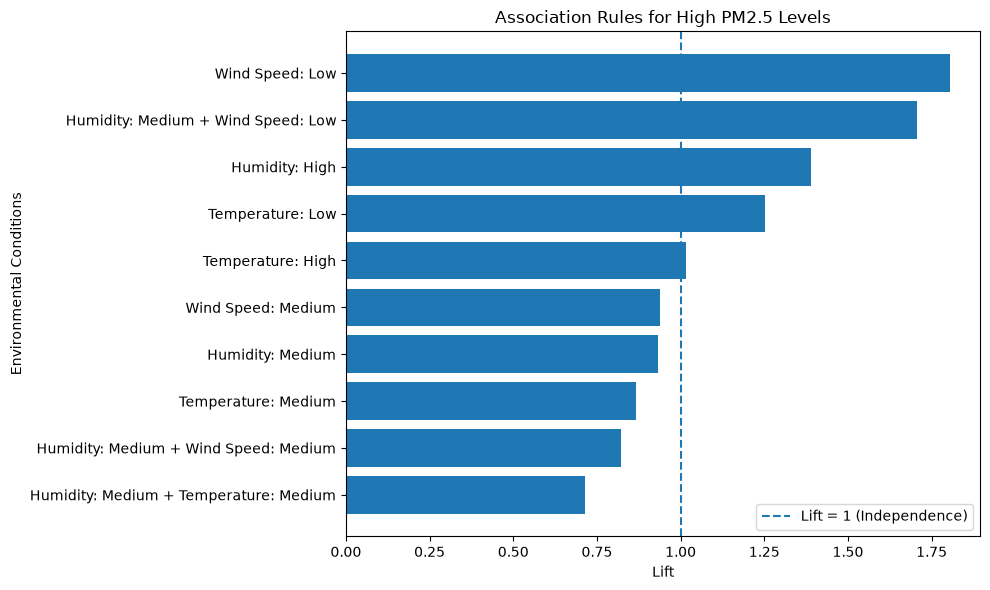

In [70]:
# Prepare labels for visualization

plot_df = target_rules.copy()

def format_antecedent(itemset):
    labels = []

    for item in sorted(itemset):
        label = item.replace("_Level_", ": ")
        label = label.replace("_", " ")
        labels.append(label)

    return " + ".join(labels)


plot_df["condition"] = plot_df["antecedents"].apply(
    format_antecedent
)

plot_df = plot_df.sort_values(
    by="lift",
    ascending=True
)

# Plot lift values

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["condition"],
    plot_df["lift"]
)

plt.axvline(
    x=1,
    linestyle="--",
    label="Lift = 1 (Independence)"
)

plt.xlabel("Lift")
plt.ylabel("Environmental Conditions")
plt.title("Association Rules for High PM2.5 Levels")

plt.legend()
plt.tight_layout()
plt.show()

### Results and Discussion

The Apriori algorithm identified 90 frequent itemsets using a minimum support threshold of 0.05. Based on these itemsets, 300 association rules were generated.

We focused on 10 rules where the consequent was **PM25_Level_High**.

The main findings are:

- **Low wind speed** showed the strongest positive association with high PM2.5 levels, with a lift of 1.804 and a confidence of 44.88%.
- **High humidity** was also positively associated with high PM2.5 levels, with a lift of 1.390.
- **Low temperature** showed a weaker positive association, with a lift of 1.252.
- **High temperature** had a lift close to 1 (1.015), indicating almost no association.
- Medium wind speed, medium humidity, and medium temperature showed negative associations with high PM2.5 levels.

Overall, the results suggest that low wind speed is an important environmental condition associated with high PM2.5 concentrations in the analyzed dataset.

These findings describe statistical associations rather than causal relationships. Further investigation would be needed to establish causal effects.

### Function Organization

To improve code reusability and readability, the main steps of the frequent pattern mining workflow are organized into reusable functions.

Each function has clearly defined inputs and outputs, allowing the analysis to be reproduced with different datasets or parameter settings.

In [71]:
# Function 1: Discretize environmental variables

def discretize_environmental_data(daily_data, columns):
    """
    Name:
        discretize_environmental_data

    Input:
        daily_data: DataFrame containing daily environmental measurements.
        columns: List of numerical variables to discretize.

    Output:
        mining_data: DataFrame containing categorical environmental levels.
        thresholds: DataFrame containing Q1 and Q3 thresholds.
    """

    thresholds = daily_data[columns].quantile([0.25, 0.75])

    mining_data = daily_data.dropna(
        subset=columns
    ).copy()

    for column in columns:
        q1 = thresholds.loc[0.25, column]
        q3 = thresholds.loc[0.75, column]

        mining_data[column + "_Level"] = pd.cut(
            mining_data[column],
            bins=[-np.inf, q1, q3, np.inf],
            labels=["Low", "Medium", "High"]
        )

    return mining_data, thresholds

In [72]:
# Define numerical variables

analysis_columns = [
    "PM25",
    "Humidity",
    "Temperature",
    "Wind_Speed"
]

# Apply discretization

mining_df, thresholds = discretize_environmental_data(
    daily_df,
    analysis_columns
)

print("Mining dataset shape:", mining_df.shape)

print("\nDiscretization thresholds:")
display(thresholds)

print("\nCategorical level distribution:")
for column in analysis_columns:
    print(f"\n{column}:")
    display(mining_df[column + "_Level"].value_counts())

Mining dataset shape: (71585, 10)

Discretization thresholds:


,PM25,Humidity,Temperature,Wind_Speed
0.25,8.958333,53.791386,11.548742,1.543642
0.75,17.912190,75.831245,23.914223,3.253897



Categorical level distribution:

PM25:


PM25_Level
Medium    35793
Low       17986
High      17806
Name: count, dtype: int64


Humidity:


Humidity_Level
Medium    35792
Low       17897
High      17896
Name: count, dtype: int64


Temperature:


Temperature_Level
Medium    35803
High      17907
Low       17875
Name: count, dtype: int64


Wind_Speed:


Wind_Speed_Level
Medium    35792
Low       17897
High      17896
Name: count, dtype: int64

### Function 2 — Transaction Encoding

This function converts categorical environmental variables into a Boolean transaction matrix using one-hot encoding.

Each station-day observation is represented by a set of environmental condition items. The resulting transaction matrix is used as input for the Apriori algorithm.

In [73]:
# Function 2: Create one-hot encoded transactions

def create_transactions(mining_data, columns):
    """
    Name:
        create_transactions

    Input:
        mining_data: DataFrame containing categorical environmental variables.
        columns: List of categorical variable names.

    Output:
        transactions: Boolean one-hot encoded transaction DataFrame.
    """

    transactions = pd.get_dummies(
        mining_data[columns],
        prefix=columns,
        dtype=bool
    )

    return transactions

In [74]:
# Define categorical variables

categorical_columns = [
    "PM25_Level",
    "Humidity_Level",
    "Temperature_Level",
    "Wind_Speed_Level"
]

# Create transaction matrix

transactions = create_transactions(
    mining_df,
    categorical_columns
)

print("Transaction dataset shape:", transactions.shape)

print("\nNumber of items per transaction:")
display(
    transactions.sum(axis=1).value_counts().sort_index()
)

print("\nFirst five transactions:")
display(transactions.head())

Transaction dataset shape: (71585, 12)

Number of items per transaction:


4    71585
Name: count, dtype: int64


First five transactions:


,PM25_Level_Low,PM25_Level_Medium,PM25_Level_High,Humidity_Level_Low,Humidity_Level_Medium,Humidity_Level_High,Temperature_Level_Low,Temperature_Level_Medium,Temperature_Level_High,Wind_Speed_Level_Low,Wind_Speed_Level_Medium,Wind_Speed_Level_High
0,False,False,True,False,True,False,False,True,False,False,True,False
1,False,True,False,False,True,False,False,True,False,False,True,False
2,False,True,False,False,True,False,False,True,False,False,True,False
3,True,False,False,False,True,False,False,True,False,False,True,False
4,True,False,False,False,True,False,False,True,False,False,True,False


### Function 3 — Apriori Frequent Itemset Mining

This function applies the Apriori algorithm to identify frequent combinations of environmental conditions.

The minimum support threshold determines the minimum frequency required for an itemset to be considered frequent.

The maximum itemset length is set to 4, corresponding to the four environmental variables used in this analysis.

In [75]:
# Function 3: Apply the Apriori algorithm

def mine_frequent_itemsets(transactions, min_support=0.05, max_len=4):
    """
    Name:
        mine_frequent_itemsets

    Input:
        transactions: Boolean transaction DataFrame.
        min_support: Minimum support threshold.
        max_len: Maximum number of items in an itemset.

    Output:
        frequent_itemsets: DataFrame containing frequent itemsets and their support.
    """

    frequent_itemsets = apriori(
        transactions,
        min_support=min_support,
        use_colnames=True,
        max_len=max_len
    )

    frequent_itemsets = frequent_itemsets.sort_values(
        by="support",
        ascending=False
    ).reset_index(drop=True)

    return frequent_itemsets

In [76]:
# Apply Apriori frequent itemset mining

frequent_itemsets = mine_frequent_itemsets(
    transactions,
    min_support=0.05,
    max_len=4
)

print("Number of frequent itemsets:", len(frequent_itemsets))

print("\nTop 20 frequent itemsets:")
display(frequent_itemsets.head(20))

Number of frequent itemsets: 90

Top 20 frequent itemsets:


,support,itemsets
0,0.500147,(Temperature_Level_Medium)
1,0.500007,(PM25_Level_Medium)
2,0.499993,(Wind_Speed_Level_Medium)
3,0.499993,(Humidity_Level_Medium)
4,0.318852,"(Humidity_Level_Medium, Temperature_Level_Medium)"
5,0.262234,"(Wind_Speed_Level_Medium, PM25_Level_Medium)"
6,0.258560,"(Wind_Speed_Level_Medium, Temperature_Level_Me..."
7,0.251366,"(Humidity_Level_Medium, PM25_Level_Medium)"
8,0.251254,(PM25_Level_Low)
9,0.250150,(Temperature_Level_High)


### Function 4 — Association Rule Mining

This function generates association rules from frequent itemsets.

We use confidence as the evaluation metric during rule generation, with a minimum threshold of 0.1.

The resulting rules include support, confidence, and lift, which help evaluate relationships between environmental conditions and high PM2.5 levels.

In [77]:
# Function 4: Generate association rules

def generate_association_rules(frequent_itemsets, min_confidence=0.1):
    """
    Name:
        generate_association_rules

    Input:
        frequent_itemsets: DataFrame containing frequent itemsets.
        min_confidence: Minimum confidence threshold.

    Output:
        rules: DataFrame containing association rules and evaluation metrics.
    """

    rules = association_rules(
        frequent_itemsets,
        metric="confidence",
        min_threshold=min_confidence
    )

    return rules

In [78]:
# Generate association rules

rules = generate_association_rules(
    frequent_itemsets,
    min_confidence=0.1
)

print("Total number of association rules:", len(rules))

print("\nTop 10 rules sorted by lift:")

display(
    rules.sort_values(
        by="lift",
        ascending=False
    )[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].head(10)
)

Total number of association rules: 300

Top 10 rules sorted by lift:


,antecedents,consequents,support,confidence,lift
197,"(Wind_Speed_Level_High, Temperature_Level_High)",(Humidity_Level_Low),0.059803,0.908339,3.633202
200,(Humidity_Level_Low),"(Wind_Speed_Level_High, Temperature_Level_High)",0.059803,0.239202,3.633202
233,"(Wind_Speed_Level_Medium, Temperature_Level_High)","(Humidity_Level_Low, PM25_Level_Medium)",0.057708,0.477848,3.431315
236,"(Humidity_Level_Low, PM25_Level_Medium)","(Wind_Speed_Level_Medium, Temperature_Level_High)",0.057708,0.414385,3.431315
229,"(Wind_Speed_Level_Medium, Humidity_Level_Low, ...",(Temperature_Level_High),0.057708,0.823729,3.292937
240,(Temperature_Level_High),"(Wind_Speed_Level_Medium, Humidity_Level_Low, ...",0.057708,0.230692,3.292937
232,"(Wind_Speed_Level_Medium, Humidity_Level_Low)","(Temperature_Level_High, PM25_Level_Medium)",0.057708,0.475155,3.282253
237,"(Temperature_Level_High, PM25_Level_Medium)","(Wind_Speed_Level_Medium, Humidity_Level_Low)",0.057708,0.398630,3.282253
82,(Temperature_Level_High),"(Humidity_Level_Low, PM25_Level_Medium)",0.113362,0.453175,3.254139
79,"(Humidity_Level_Low, PM25_Level_Medium)",(Temperature_Level_High),0.113362,0.814023,3.254139


### Function 5 — Filter Target Association Rules

This function selects association rules where high PM2.5 is the consequent.

It allows us to focus specifically on environmental conditions associated with high PM2.5 levels.

In [79]:
# Function 5: Filter rules targeting high PM2.5

def filter_target_rules(rules, target_item="PM25_Level_High"):
    """
    Name:
        filter_target_rules

    Input:
        rules: DataFrame containing association rules.
        target_item: Target item to identify in the consequent.

    Output:
        target_rules: Filtered rules sorted by lift.
    """

    target_rules = rules[
        rules["consequents"].apply(
            lambda itemset: itemset == frozenset([target_item])
        )
    ].copy()

    target_rules = target_rules.sort_values(
        by="lift",
        ascending=False
    ).reset_index(drop=True)

    return target_rules

In [80]:
# Filter association rules targeting high PM2.5

target_rules = filter_target_rules(
    rules,
    target_item="PM25_Level_High"
)

print("Number of target rules:", len(target_rules))

display(
    target_rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ]
)

Number of target rules: 10


,antecedents,consequents,support,confidence,lift
0,(Wind_Speed_Level_Low),(PM25_Level_High),0.112202,0.448790,1.804260
1,"(Humidity_Level_Medium, Wind_Speed_Level_Low)",(PM25_Level_High),0.054425,0.424308,1.705836
2,(Humidity_Level_High),(PM25_Level_High),0.086429,0.345720,1.389888
3,(Temperature_Level_Low),(PM25_Level_High),0.077782,0.311497,1.252301
4,(Temperature_Level_High),(PM25_Level_High),0.063156,0.252471,1.015003
5,(Wind_Speed_Level_Medium),(PM25_Level_High),0.116659,0.233320,0.938012
6,(Humidity_Level_Medium),(PM25_Level_High),0.115904,0.231812,0.931946
7,(Temperature_Level_Medium),(PM25_Level_High),0.107802,0.215541,0.866532
8,"(Wind_Speed_Level_Medium, Humidity_Level_Medium)",(PM25_Level_High),0.051002,0.204687,0.822897
9,"(Humidity_Level_Medium, Temperature_Level_Medium)",(PM25_Level_High),0.056632,0.177612,0.714050


### Function 6 — Visualize Association Rules

This function visualizes the lift values of association rules targeting high PM2.5 levels.

A reference line at lift = 1 is included to distinguish positive and negative associations.

In [81]:
# Function 6: Visualize association rules

def plot_association_rules(target_rules):
    """
    Name:
        plot_association_rules

    Input:
        target_rules: DataFrame containing rules targeting high PM2.5.

    Output:
        Displays a horizontal bar chart of lift values.
    """

    plot_data = target_rules.copy()

    def format_antecedent(itemset):
        labels = []

        for item in sorted(itemset):
            label = item.replace("_Level_", ": ")
            label = label.replace("_", " ")
            labels.append(label)

        return " + ".join(labels)

    plot_data["condition"] = plot_data["antecedents"].apply(
        format_antecedent
    )

    plot_data = plot_data.sort_values(
        by="lift",
        ascending=True
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        plot_data["condition"],
        plot_data["lift"]
    )

    plt.axvline(
        x=1,
        linestyle="--",
        label="Lift = 1 (Independence)"
    )

    plt.xlabel("Lift")
    plt.ylabel("Environmental Conditions")
    plt.title("Association Rules for High PM2.5 Levels")

    plt.legend()
    plt.tight_layout()
    plt.show()

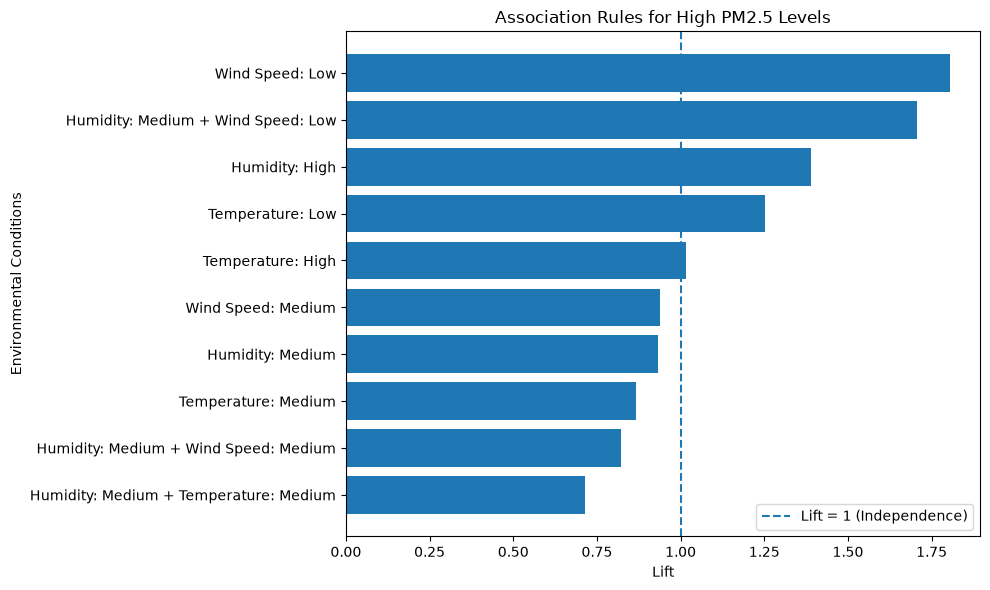

In [82]:
# Visualize rules targeting high PM2.5

plot_association_rules(target_rules)

In [83]:
def load_temporal_spatial_data(file_path):
    """
    Load the columns needed for temporal and spatial analysis.

    Input:
        file_path: Path to athens_data.csv.

    Output:
        DataFrame with Date, station_name, PM25 and coordinates
        when latitude and longitude are available.
    """
    file_path = Path(file_path)

    if not file_path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {file_path.resolve()}"
        )

    # Read the header first to identify coordinate columns.
    columns = pd.read_csv(file_path, nrows=0).columns.tolist()

    normalized = {
        "".join(char for char in column.lower() if char.isalnum()): column
        for column in columns
    }

    latitude_column = next(
        (
            normalized[name]
            for name in ["latitude", "lat", "stationlatitude", "stationlat"]
            if name in normalized
        ),
        None
    )

    longitude_column = next(
        (
            normalized[name]
            for name in [
                "longitude", "lon", "lng", "long",
                "stationlongitude", "stationlon"
            ]
            if name in normalized
        ),
        None
    )

    selected_columns = ["Date", "station_name", "PM2.5"]
    rename_columns = {"PM2.5": "PM25"}

    if latitude_column is not None and longitude_column is not None:
        selected_columns += [latitude_column, longitude_column]

        rename_columns[latitude_column] = "latitude"
        rename_columns[longitude_column] = "longitude"
    else:
        print("Coordinates not detected. Available CSV columns:")
        print(columns)

    data = pd.read_csv(
        file_path,
        usecols=selected_columns
    ).rename(columns=rename_columns)

    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
    data["PM25"] = pd.to_numeric(data["PM25"], errors="coerce")

    # Negative or infinite concentrations are treated as missing.
    data["PM25"] = data["PM25"].replace([np.inf, -np.inf], np.nan)
    data.loc[data["PM25"] < 0, "PM25"] = np.nan

    return data.dropna(subset=["Date", "station_name"])

In [84]:
def forecast_daily_pm25(data, test_days=30, forecast_days=30):
    """
    Forecast the daily PM2.5 monitoring-network average.

    Input:
        data: DataFrame with Date, station_name and PM25.
        test_days: Number of final days reserved for evaluation.
        forecast_days: Number of days to forecast after the dataset ends.

    Output:
        Dictionary containing observations, evaluation results,
        performance metrics, future forecasts and the figure.
    """
    if test_days < 1 or forecast_days < 1:
        raise ValueError("Forecast horizons must be positive.")

    working = data[["Date", "station_name", "PM25"]].copy()
    working["day"] = working["Date"].dt.floor("D")

    # Calculate one daily average per station.
    station_daily = (
        working.groupby(["station_name", "day"])["PM25"]
        .mean()
        .reset_index()
    )

    # Give each available station the same weight.
    daily = (
        station_daily.groupby("day")["PM25"]
        .mean()
        .sort_index()
        .asfreq("D")
    )

    if len(daily) < test_days + 28:
        raise ValueError("Not enough history for training and evaluation.")

    # Keep the final period unseen during model fitting.
    train_raw = daily.iloc[:-test_days]
    test = daily.iloc[-test_days:]

    # Fill gaps using training observations only.
    train = train_raw.ffill().bfill()

    if train.isna().any() or test.notna().sum() == 0:
        raise ValueError("Insufficient valid observations.")

    model = ExponentialSmoothing(
        train,
        trend="add",
        damped_trend=True,
        seasonal="add",
        seasonal_periods=7,
        initialization_method="estimated"
    ).fit(optimized=True)

    # Concentration forecasts cannot be negative.
    predictions = model.forecast(test_days).clip(lower=0)

    # Baseline: repeat the final seven training observations.
    baseline = np.resize(
        train.iloc[-7:].to_numpy(),
        test_days
    )

    comparison = pd.DataFrame({
        "Observed": test,
        "Holt_Winters": predictions.to_numpy(),
        "Seasonal_naive": baseline
    })

    # Evaluate only genuinely observed test values.
    observed_test = comparison.dropna(subset=["Observed"])

    metrics = pd.DataFrame([
        {
            "Model": column,
            "MAE": mean_absolute_error(
                observed_test["Observed"],
                observed_test[column]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                observed_test["Observed"],
                observed_test[column]
            ))
        }
        for column in ["Holt_Winters", "Seasonal_naive"]
    ])

    # Refit using all historical observations for the future forecast.
    complete_history = daily.ffill().bfill()

    final_model = ExponentialSmoothing(
        complete_history,
        trend="add",
        damped_trend=True,
        seasonal="add",
        seasonal_periods=7,
        initialization_method="estimated"
    ).fit(optimized=True)

    future = final_model.forecast(forecast_days).clip(lower=0)
    future = future.rename("Predicted_PM25").to_frame()
    future.index.name = "Date"

    fig, axes = plt.subplots(2, 1, figsize=(13, 9))

    axes[0].plot(
        train_raw.tail(90),
        label="Training observations",
        color="steelblue"
    )
    axes[0].plot(test, label="Test observations", color="black")
    axes[0].plot(
        comparison["Holt_Winters"],
        label="Holt-Winters",
        color="darkorange"
    )
    axes[0].plot(
        comparison["Seasonal_naive"],
        label="Seasonal naive",
        linestyle="--",
        color="green"
    )
    axes[0].set_title("Query 3: Forecast evaluation")
    axes[0].legend()

    axes[1].plot(
        daily.tail(120),
        label="Historical observations",
        color="steelblue"
    )
    axes[1].plot(
        future["Predicted_PM25"],
        label=f"Next {forecast_days} days",
        color="darkorange"
    )
    axes[1].set_title("Future daily PM2.5 forecast")
    axes[1].legend()

    for ax in axes:
        ax.set_xlabel("Date")
        ax.set_ylabel("PM2.5 concentration")
        ax.grid(alpha=0.3)

    fig.tight_layout()
    plt.show()

    return {
        "daily": daily,
        "evaluation": comparison,
        "metrics": metrics,
        "future": future,
        "figure": fig
    }

In [85]:
def cluster_monitoring_stations(data, eps_km=2.0, min_samples=3):
    """
    Group monitoring stations by geographical proximity.

    Input:
        data: DataFrame with station_name, Date, PM25,
              latitude and longitude in decimal degrees.
        eps_km: DBSCAN neighborhood radius in kilometers.
        min_samples: Minimum stations in a dense neighborhood.

    Output:
        Dictionary containing station clusters, cluster summaries
        and the figure.
    """
    required = {"latitude", "longitude"}

    if not required.issubset(data.columns):
        raise ValueError(
            "Spatial clustering requires latitude and longitude. "
            "Check the CSV column names or provide station coordinates."
        )

    working = data.copy()

    for column in ["latitude", "longitude"]:
        working[column] = pd.to_numeric(
            working[column], errors="coerce"
        )

    # Keep valid geographical coordinates.
    valid_coordinates = working[
        working["latitude"].between(-90, 90)
        & working["longitude"].between(-180, 180)
    ]

    # Verify that each station has a fixed location.
    coordinate_counts = (
        valid_coordinates.groupby("station_name")[
            ["latitude", "longitude"]
        ].nunique()
    )

    if (coordinate_counts > 1).any().any():
        raise ValueError(
            "Some stations have multiple coordinates. "
            "Check their locations before clustering."
        )

    locations = (
        valid_coordinates[
            ["station_name", "latitude", "longitude"]
        ]
        .drop_duplicates("station_name")
    )

    # Calculate mean pollution from daily station averages.
    working["day"] = working["Date"].dt.floor("D")

    station_daily = (
        working.groupby(["station_name", "day"])["PM25"]
        .mean()
        .reset_index()
    )

    pollution = (
        station_daily.groupby("station_name")
        .agg(
            mean_PM25=("PM25", "mean"),
            observed_days=("PM25", "count")
        )
        .reset_index()
    )

    stations = locations.merge(
        pollution,
        on="station_name",
        how="inner",
        validate="one_to_one"
    )

    if len(stations) < min_samples:
        raise ValueError("Not enough stations with valid coordinates.")

    # Haversine requires [latitude, longitude] in radians.
    coordinates_radians = np.radians(
        stations[["latitude", "longitude"]].to_numpy()
    )

    earth_radius_km = 6371.0088

    stations["cluster"] = DBSCAN(
        eps=eps_km / earth_radius_km,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree"
    ).fit_predict(coordinates_radians)

    # Exclude spatial noise from the cluster comparison.
    summary = (
        stations[stations["cluster"] != -1]
        .groupby("cluster")
        .agg(
            number_of_stations=("station_name", "size"),
            mean_PM25=("mean_PM25", "mean"),
            min_station_PM25=("mean_PM25", "min"),
            max_station_PM25=("mean_PM25", "max")
        )
        .sort_values("mean_PM25", ascending=False)
        .reset_index()
    )

    number_of_clusters = stations.loc[
        stations["cluster"] != -1, "cluster"
    ].nunique()

    print("Number of geographical clusters:", number_of_clusters)
    print("Stations classified as noise:", (stations["cluster"] == -1).sum())

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    labels = sorted(stations["cluster"].unique())
    colors = plt.get_cmap("tab20")

    for position, label in enumerate(labels):
        subset = stations[stations["cluster"] == label]

        axes[0].scatter(
            subset["longitude"],
            subset["latitude"],
            color="gray" if label == -1 else colors(position % 20),
            marker="x" if label == -1 else "o",
            s=65,
            label="Noise" if label == -1 else f"Cluster {label}"
        )

    # Approximate geographical aspect ratio for the Athens area.
    mean_latitude = stations["latitude"].mean()
    axes[0].set_aspect(1 / np.cos(np.radians(mean_latitude)))

    axes[0].set_title("Query 4: Geographical station clusters")
    axes[0].set_xlabel("Longitude")
    axes[0].set_ylabel("Latitude")
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.3)

    if not summary.empty:
        axes[1].bar(
            summary["cluster"].astype(str),
            summary["mean_PM25"],
            color="coral"
        )
    else:
        axes[1].text(
            0.5, 0.5,
            "No clusters found.\nReview eps_km and min_samples.",
            ha="center",
            va="center",
            transform=axes[1].transAxes
        )

    axes[1].set_title("Average PM2.5 by geographical cluster")
    axes[1].set_xlabel("Cluster")
    axes[1].set_ylabel("Mean station PM2.5")
    axes[1].grid(axis="y", alpha=0.3)

    fig.tight_layout()
    plt.show()

    return {
        "stations": stations,
        "summary": summary,
        "figure": fig
    }

QUERY 3 — TEMPORAL FORECASTING


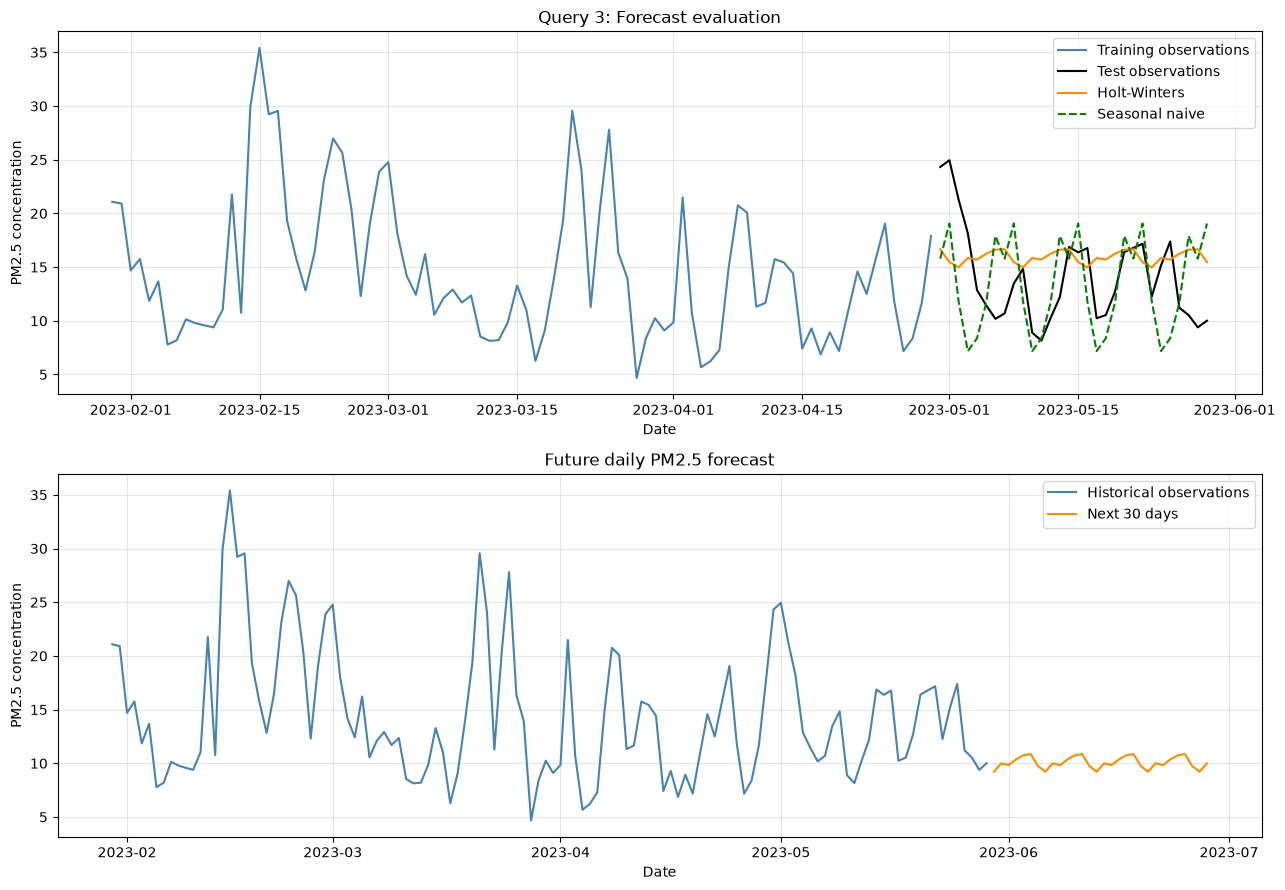


Forecast evaluation:


,Model,MAE,RMSE
0,Holt_Winters,4.038585,4.832765
1,Seasonal_naive,4.339170,5.412688



Future predictions:


,Predicted_PM25
Date,
2023-05-30,9.217758
2023-05-31,9.998189
2023-06-01,9.831404
2023-06-02,10.352991
2023-06-03,10.742720
2023-06-04,10.861587
2023-06-05,9.735712
2023-06-06,9.217758
2023-06-07,9.998189



QUERY 4 — SPATIAL CLUSTERING
Number of geographical clusters: 5
Stations classified as noise: 32


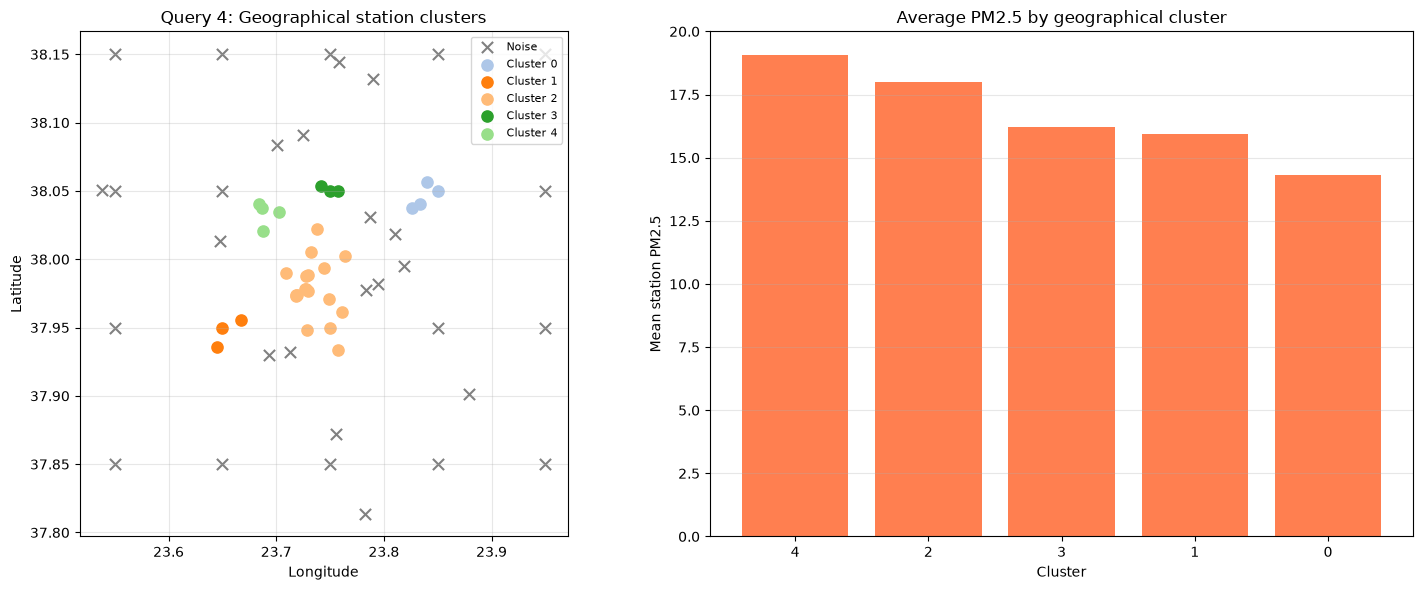

,cluster,number_of_stations,mean_PM25,min_station_PM25,max_station_PM25
0,4,4,19.049957,17.685822,20.922076
1,2,18,17.981903,13.042619,23.033377
2,3,3,16.216233,13.260216,20.724213
3,1,3,15.918589,13.853156,18.754278
4,0,4,14.309036,11.228887,15.718113


,station_name,latitude,longitude,mean_PM25,observed_days,cluster
0,Athens CAMS station 0,38.15,23.55,9.562700,1124,-1
1,Athens CAMS station 9,37.85,23.75,11.284817,1124,-1
2,Athens CAMS station 1,38.15,23.65,9.753861,1124,-1
3,Athens CAMS station 10,37.85,23.85,10.604975,1124,-1
4,Athens CAMS station 11,37.85,23.95,9.794068,1124,-1
5,Athens CAMS station 13,38.15,23.85,10.148346,1124,-1
6,Athens CAMS station 8,37.85,23.65,11.450991,1124,-1
7,Athens CAMS station 14,38.15,23.95,9.486614,1124,-1
8,Athens CAMS station 15,38.05,23.55,12.186203,1124,-1
9,Athens CAMS station 16,38.05,23.65,13.261977,1124,-1


In [86]:
def main(file_path="data/athens_data.csv"):
    """
    Run both analyses.

    Input:
        file_path: Path to the Athens CSV.

    Output:
        Dictionary with temporal and spatial results.
    """
    data = load_temporal_spatial_data(file_path)

    print("QUERY 3 — TEMPORAL FORECASTING")

    temporal_results = forecast_daily_pm25(
        data,
        test_days=30,
        forecast_days=30
    )

    print("\nForecast evaluation:")
    display(temporal_results["metrics"])

    print("\nFuture predictions:")
    display(temporal_results["future"])

    print("\nQUERY 4 — SPATIAL CLUSTERING")

    spatial_results = None

    if {"latitude", "longitude"}.issubset(data.columns):
        spatial_results = cluster_monitoring_stations(
            data,
            eps_km=2.0,
            min_samples=3
        )

        display(spatial_results["summary"])
        display(spatial_results["stations"].head(10))
    else:
        print(
            "Spatial analysis requires station coordinates. "
            "The temporal analysis has been completed."
        )

    return {
        "temporal": temporal_results,
        "spatial": spatial_results
    }


results = main("data/athens_data.csv")